# 2. Final CCLE comparison: saved models + same-gene baselines

This notebook compares saved 80/20 model results from:

- `results_xgb/`
- `res_xgb_zbig/`
- `results_enet/`
- `res_enet_zbig/`

and adds two simple same-name gene baselines:

- **Pearson same-gene baseline**: for proteins where `full_pearson100[protein, same-name gene] >= 0.7`, predict protein abundance using the same-name RNA gene value.
- **Spearman same-gene baseline**: same idea using `full_spearman100`.

The same-gene baselines are evaluated on a reproducible random 20% test split.

Important: the same-gene baselines use raw gene expression values directly as predictions. Pearson/cosine can be meaningful for direction/ranking, but MSE may look poor if RNA and protein scales differ.

In [1]:
from pathlib import Path
import json
import lzma
import pickle
import re
import warnings

import h5py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# -----------------------------
# Project paths
# -----------------------------
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"

X_PATH = DATA_DIR / "transcriptomics_filtered.joblib"
Y_PATH = DATA_DIR / "proteomics_matched.joblib"
PEARSON_PATH = DATA_DIR / "full_pearson100.joblib"
SPEARMAN_PATH = DATA_DIR / "full_spearman100.joblib"

MODEL_DIRS = {
    "xgb": ROOT / "results_xgb",
    "xgb_zbig": ROOT / "res_xgb_zbig",
    "enet": ROOT / "results_enet",
    "enet_zbig": ROOT / "res_enet_zbig",
}

# -----------------------------
# Thresholds and display settings
# -----------------------------
RANDOM_SEED = 42
BASELINE_CORR_THRESHOLD = 0.70
TEST_FRACTION = 0.20

PEARSON_GOOD_THRESHOLD = 0.70
COSINE_GOOD_THRESHOLD = 0.70
MSE_GOOD_PERCENTILE = 25   # lower MSE is better; good if MSE <= this percentile among best-MSE rows

MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT = 200

# Scaling for same-gene baseline. Leave False to match the requested raw-gene-as-prediction behavior.
SCALE_GENE_BASELINE_WITH_TRAIN_LINEAR_MODEL = False

print("Root:", ROOT)
print("Data dir:", DATA_DIR)
print("Model folders:")
for name, folder in MODEL_DIRS.items():
    print(f"  {name:10s}: {folder}  exists={folder.exists()}")

Root: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison
Data dir: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\data
Model folders:
  xgb       : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\results_xgb  exists=True
  xgb_zbig  : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\res_xgb_zbig  exists=True
  enet      : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\results_enet  exists=True
  enet_zbig : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\res_enet_zbig  exists=True


In [2]:
# Shared CCLE validation utilities
from pathlib import Path as _Path
import sys as _sys

# Make src/utils_ccle.py importable from repo root, notebooks/, notebooks2/, or this folder.
for _candidate in [
    _Path.cwd(),
    _Path.cwd().parent,
    _Path.cwd() / "notebooks",
    _Path.cwd().parent / "notebooks",
    _Path.cwd() / "notebooks2",
    _Path.cwd().parent / "notebooks2",
]:
    if (_candidate / "src" / "utils_ccle.py").exists():
        if str(_candidate) not in _sys.path:
            _sys.path.insert(0, str(_candidate))
        break
else:
    raise FileNotFoundError("Could not find src/utils_ccle.py from the current notebook location.")

import src.utils_ccle as uc
from src.utils_ccle import *
uc.set_module_globals(globals())
print("Loaded utilities:", uc.__file__)

Loaded utilities: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\src\utils_ccle.py


## 1. Load transcriptomics, proteomics, and correlation matrices

In [3]:
for p in [X_PATH, Y_PATH, PEARSON_PATH, SPEARMAN_PATH]:
    require_file(p)

X_raw = joblib.load(X_PATH)
Y_raw = joblib.load(Y_PATH)
pearson_corr_obj = joblib.load(PEARSON_PATH)
spearman_corr_obj = joblib.load(SPEARMAN_PATH)

X = X_raw.copy()
Y0 = Y_raw.copy()

X.index = X.index.map(str)
X.columns = X.columns.map(str)
Y0.index = Y0.index.map(str)
Y0.columns = Y0.columns.map(str)

# Detect proteomics orientation and convert to rows=samples, columns=proteins.
x_samples = set(X.index)
y_index_overlap = len(x_samples & set(Y0.index))
y_column_overlap = len(x_samples & set(Y0.columns))

if y_index_overlap >= y_column_overlap:
    Y = Y0.copy()
    proteomics_orientation = "samples_as_rows__proteins_as_columns"
else:
    Y = Y0.T.copy()
    proteomics_orientation = "proteins_as_rows__samples_as_columns__transposed"

Y.index = Y.index.map(str)
Y.columns = Y.columns.map(str)

common_samples = X.index.intersection(Y.index)
X = X.loc[common_samples].copy()
Y = Y.loc[common_samples].copy()

print("Loaded data")
print("- Transcriptomics shape:", X.shape, "(samples x genes)")
print("- Proteomics shape:     ", Y.shape, "(samples x proteins)")
print("- Proteomics orientation:", proteomics_orientation)
print("- Common samples:", len(common_samples))
print("- First samples:", list(common_samples[:5]))
print("- First genes:", list(X.columns[:5]))
print("- First proteins:", list(Y.columns[:5]))

print("\nCorrelation objects:")
print("- Pearson type:", type(pearson_corr_obj), "shape:", getattr(pearson_corr_obj, "shape", None))
print("- Spearman type:", type(spearman_corr_obj), "shape:", getattr(spearman_corr_obj, "shape", None))

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Loaded data
- Transcriptomics shape: (369, 22614) (samples x genes)
- Proteomics shape:      (369, 5113) (samples x proteins)
- Proteomics orientation: samples_as_rows__proteins_as_columns
- Common samples: 369
- First samples: ['MDAMB468_BREAST', 'SH4_SKIN', 'AU565_BREAST', 'KMRC1_KIDNEY', 'CAL51_BREAST']
- First genes: ['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2ML1']
- First proteins: ['A2M', 'AAAS', 'AACS', 'AAGAB', 'AAK1']

Correlation objects:
- Pearson type: <class 'pandas.core.frame.DataFrame'> shape: (5113, 51989)
- Spearman type: <class 'pandas.core.frame.DataFrame'> shape: (5113, 51989)


## 2. Helper functions for metrics, correlation lookup, and H5 result loading

## 3. Load saved XGB/ENet result summaries and merge with same-gene baselines

In [4]:
# ============================================================
# Load saved XGB/ENet result summaries
# Do NOT build all_results here yet.
# The same-gene baselines will be rebuilt after reading the H5 test split.
# ============================================================

model_rows = []
folder_counts = {}

for label, folder in MODEL_DIRS.items():
    folder = Path(folder)
    files = sorted(folder.glob("*.h5")) if folder.exists() else []
    folder_counts[label] = len(files)

    for path in files:
        row = load_h5_summary(path, label)

        # Make sure h5_path exists even if load_h5_summary did not include it.
        if "h5_path" not in row:
            row["h5_path"] = str(path)

        model_rows.append(row)

model_results = pd.DataFrame(model_rows)

if len(model_results):
    for c in [
        "test_mse",
        "test_pearson_corr",
        "test_cosine_similarity",
        "selected_feature_count",
        "train_n",
        "test_n",
        "select_k",
        "file_size_mb",
    ]:
        if c in model_results.columns:
            model_results[c] = pd.to_numeric(model_results[c], errors="coerce")

print("Saved model file counts")
for label, n in folder_counts.items():
    print(f"- {label:12s}: {n:6d} H5 files")

print("\nSaved model result table")
print("- Saved model rows:", len(model_results))
print("- Unique proteins: ", model_results["protein"].nunique() if len(model_results) and "protein" in model_results.columns else 0)

if len(model_results) and "load_error" in model_results.columns:
    n_errors = int(model_results["load_error"].notna().sum())
    print("- H5 load errors:  ", n_errors)

    if n_errors:
        print("\nExample load errors:")
        display(model_results.loc[model_results["load_error"].notna(), ["h5_path", "load_error"]].head(10))

if len(model_results):
    print("\nRows by run_label:")
    display(
        model_results.groupby("run_label")["protein"]
        .nunique()
        .sort_values(ascending=False)
        .to_frame("proteins")
    )

    print("\nMetric availability:")
    display(
        model_results[["test_pearson_corr", "test_cosine_similarity", "test_mse"]]
        .notna()
        .sum()
        .to_frame("nonmissing")
    )

    display(model_results.head())

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Saved model file counts
- xgb         :  20462 H5 files
- xgb_zbig    :   5113 H5 files
- enet        :  20602 H5 files
- enet_zbig   :   5113 H5 files

Saved model result table
- Saved model rows: 51290
- Unique proteins:  5113
- H5 load errors:   0

Rows by run_label:


,proteins
run_label,
enet | none | fast | k2000,5113
enet | ranking | fast | k2000,5113
enet | unknown | fast | k2000,5113
enet | zscore | fast | k2000,5113
enet_zbig | zscore | fast | k5000,5113
xgb | none | fast | k2000,5113
xgb | qbin50 | fast | k2000,5113
xgb | rank | fast | k2000,5113
xgb | zscore | fast | k2000,5113



Metric availability:


,nonmissing
test_pearson_corr,50217
test_cosine_similarity,51290
test_mse,51290


,protein,run_label,model_family,source_folder,normalization,grid_preset,select_k,h5_path,file,file_size_mb,test_mse,test_pearson_corr,test_cosine_similarity,selected_feature_count,train_n,test_n,best_params,load_error
0,A2M,xgb | none | fast | k2000,xgb,xgb,none,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_fast_k2000.h5,0.120128,0.760331,0.469012,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None
1,A2M,xgb | none | tiny | k50,xgb,xgb,none,tiny,50,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_tiny_k50.h5,0.083029,0.753375,0.477427,0.558124,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None
2,A2M,xgb | qbin50 | fast | k2000,xgb,xgb,qbin50,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_fast_k2000.h5,2.574004,0.751074,0.466232,0.560768,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None
3,A2M,xgb | qbin50 | tiny | k50,xgb,xgb,qbin50,tiny,50,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_tiny_k50.h5,2.617776,0.778497,0.451791,0.539072,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None
4,A2M,xgb | rank | fast | k2000,xgb,xgb,rank,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_rank_fast_k2000.h5,7.608312,0.760331,0.469012,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None


## 4. Build same-gene Pearson/Spearman baseline results on the same 20% test split

In [5]:
# ============================================================
# Rebuild same-gene Pearson/Spearman proxies on the exact H5 test split
# used by XGB/ENet, then create all_results.
#
# This cell is self-contained:
# - reads test_samples from H5 files
# - defines same-gene baseline helper functions if missing
# - rebuilds Pearson/Spearman proxy baselines on the same 20% test set
# - creates all_results
# ============================================================

import hashlib
import json
import numpy as np
import pandas as pd
import h5py

if "SCALE_GENE_BASELINE_WITH_TRAIN_LINEAR_MODEL" not in globals():
    SCALE_GENE_BASELINE_WITH_TRAIN_LINEAR_MODEL = False

# -----------------------------
# Fallback metric helper
# -----------------------------


# -----------------------------
# H5 split-reading helpers
# -----------------------------


# -----------------------------
# Same-gene baseline helpers
# -----------------------------


# -----------------------------
# Read the XGB/ENet H5 test split
# -----------------------------
if len(model_results) == 0:
    raise RuntimeError("model_results is empty. Run the previous model-loading cell first.")

if "h5_path" not in model_results.columns:
    raise RuntimeError("model_results has no h5_path column, so the H5 test split cannot be read.")

split_rows = []
split_samples_by_hash = {}

h5_paths = (
    model_results["h5_path"]
    .dropna()
    .astype(str)
    .loc[lambda s: s.str.len() > 0]
    .unique()
)

for path in h5_paths:
    try:
        h5_test_samples = read_test_samples_from_h5(path)

        if h5_test_samples is None:
            split_rows.append({
                "h5_path": path,
                "readable": False,
                "test_n": np.nan,
                "split_hash": None,
            })
            continue

        h5_test_samples = pd.Index(h5_test_samples.astype(str))
        h = split_hash(h5_test_samples)

        split_samples_by_hash[h] = h5_test_samples

        split_rows.append({
            "h5_path": path,
            "readable": True,
            "test_n": len(h5_test_samples),
            "split_hash": h,
        })

    except Exception as e:
        split_rows.append({
            "h5_path": path,
            "readable": False,
            "test_n": np.nan,
            "split_hash": None,
            "error": f"{type(e).__name__}: {e}",
        })

h5_split_check = pd.DataFrame(split_rows)

print("H5 test split readability")
display(
    h5_split_check
    .groupby(["readable", "split_hash"], dropna=False)
    .agg(
        files=("h5_path", "count"),
        test_n=("test_n", "median"),
    )
    .reset_index()
    .sort_values(["readable", "files"], ascending=[False, False])
)

readable = h5_split_check[h5_split_check["readable"]].copy()

if readable.empty:
    raise RuntimeError(
        "Could not read test_samples from any H5 file. "
        "The saved XGB/ENet files probably do not store the test split."
    )

unique_hashes = readable["split_hash"].dropna().unique()

if len(unique_hashes) != 1:
    print("\nDifferent H5 test splits were found:")
    display(
        readable
        .groupby("split_hash")
        .agg(
            files=("h5_path", "count"),
            test_n=("test_n", "median"),
        )
        .sort_values("files", ascending=False)
    )

    raise RuntimeError(
        f"Found {len(unique_hashes)} different H5 test splits. "
        "A single Pearson/Spearman proxy split cannot match all models."
    )


# -----------------------------
# Use exact XGB/ENet test split
# -----------------------------
model_split_hash = unique_hashes[0]
model_test_samples = pd.Index(split_samples_by_hash[model_split_hash].astype(str))

common_samples_index = pd.Index(np.asarray(common_samples, dtype=str))

old_test_samples = pd.Index(np.asarray(test_samples, dtype=str)) if "test_samples" in globals() else pd.Index([])

test_samples = model_test_samples.intersection(common_samples_index)
train_samples = pd.Index([s for s in common_samples_index if s not in set(test_samples)])

print("\nUsing the exact XGB/ENet H5 test split for Pearson/Spearman proxies")
print("- Split hash:", model_split_hash)
print("- Test samples:", len(test_samples))
print("- Train samples:", len(train_samples))
print("- Test fraction:", len(test_samples) / len(common_samples_index))

if len(old_test_samples) > 0:
    overlap = len(old_test_samples.intersection(test_samples))
    print("- Overlap with previous random proxy split:", overlap, "/", len(test_samples))

print("- First test samples:", list(test_samples[:5]))


# -----------------------------
# Build Pearson/Spearman lookups
# -----------------------------
possible_same_name = sorted(set(Y.columns.astype(str)).intersection(set(X.columns.astype(str))))

print("\nPrecomputing same-name Pearson lookup...")
pearson_lookup = build_same_name_corr_lookup_fast(pearson_corr_obj, possible_same_name)

print("Precomputing same-name Spearman lookup...")
spearman_lookup = build_same_name_corr_lookup_fast(spearman_corr_obj, possible_same_name)


# -----------------------------
# Rebuild Pearson/Spearman proxies on exact same test split
# -----------------------------
pearson_baseline, pearson_candidates, pearson_eligible = build_same_gene_baseline_from_lookup(
    pearson_lookup,
    baseline_name="same_gene_pearson_baseline",
    corr_threshold=BASELINE_CORR_THRESHOLD,
)

spearman_baseline, spearman_candidates, spearman_eligible = build_same_gene_baseline_from_lookup(
    spearman_lookup,
    baseline_name="same_gene_spearman_baseline",
    corr_threshold=BASELINE_CORR_THRESHOLD,
)

same_gene_baselines = pd.concat(
    [pearson_baseline, spearman_baseline],
    ignore_index=True,
    sort=False,
)

same_gene_baselines["train_n"] = len(train_samples)
same_gene_baselines["test_n"] = len(test_samples)
same_gene_baselines["split_hash"] = model_split_hash
same_gene_baselines["baseline_test_split_source"] = "read_from_xgb_enet_h5"


# -----------------------------
# Create final all_results
# -----------------------------
all_results = pd.concat(
    [model_results, same_gene_baselines],
    ignore_index=True,
    sort=False,
)

print("\nRebuilt same-gene proxy baseline summary")
print(f"- Pearson candidates:  {pearson_candidates}")
print(f"- Pearson eligible:    {pearson_eligible}")
print(f"- Spearman candidates: {spearman_candidates}")
print(f"- Spearman eligible:   {spearman_eligible}")
print(f"- Baseline rows total: {len(same_gene_baselines)}")

print("\nCombined result table")
print("- Saved model rows:", len(model_results))
print("- Baseline rows:   ", len(same_gene_baselines))
print("- Total rows:      ", len(all_results))
print("- Unique proteins: ", all_results["protein"].nunique() if len(all_results) else 0)

if len(all_results):
    print("\nRows by run_label:")
    display(
        all_results.groupby("run_label")["protein"]
        .nunique()
        .sort_values(ascending=False)
        .to_frame("proteins")
    )

    print("\nMetric availability:")
    display(
        all_results[["test_pearson_corr", "test_cosine_similarity", "test_mse"]]
        .notna()
        .sum()
        .to_frame("nonmissing")
    )

    print("\nMetric availability by run_label:")
    display(
        all_results.groupby("run_label")
        .agg(
            rows=("protein", "count"),
            proteins=("protein", "nunique"),
            pearson_nonmissing=("test_pearson_corr", lambda s: s.notna().sum()),
            cosine_nonmissing=("test_cosine_similarity", lambda s: s.notna().sum()),
            mse_nonmissing=("test_mse", lambda s: s.notna().sum()),
            test_n=("test_n", "median"),
        )
        .sort_values("proteins", ascending=False)
    )

    display(all_results.head())

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

H5 test split readability


,readable,split_hash,files,test_n
0,True,d0750f1c44a2,51290,74.0



Using the exact XGB/ENet H5 test split for Pearson/Spearman proxies
- Split hash: d0750f1c44a2
- Test samples: 74
- Train samples: 295
- Test fraction: 0.2005420054200542
- First test samples: ['HDMYZ_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'JHH5_LIVER', 'CAOV3_OVARY', 'K562_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'NCIH1693_LUNG']

Precomputing same-name Pearson lookup...
Precomputing same-name Spearman lookup...

Building same_gene_pearson_baseline
- Same-name protein/gene pairs possible: 4843
- Correlation lookup entries: 4843
- Test samples used: 74
- Train samples used: 295

Building same_gene_spearman_baseline
- Same-name protein/gene pairs possible: 4843
- Correlation lookup entries: 4843
- Test samples used: 74
- Train samples used: 295

Rebuilt same-gene proxy baseline summary
- Pearson candidates:  4843
- Pearson eligible:    786
- Spearman candidates: 4843
- Spearman eligible:   615
- Baseline rows total: 1401

Combined result table
- Saved model rows: 51290
- Baseline rows:    14

,proteins
run_label,
enet | none | fast | k2000,5113
enet_zbig | zscore | fast | k5000,5113
xgb | zscore | fast | k2000,5113
xgb | rank | fast | k2000,5113
xgb | qbin50 | fast | k2000,5113
xgb | none | fast | k2000,5113
xgb_zbig | zscore | current | k5000,5113
enet | zscore | fast | k2000,5113
enet | unknown | fast | k2000,5113



Metric availability:


,nonmissing
test_pearson_corr,51618
test_cosine_similarity,52691
test_mse,52691



Metric availability by run_label:


,rows,proteins,pearson_nonmissing,cosine_nonmissing,mse_nonmissing,test_n
run_label,,,,,,
enet | none | fast | k2000,5113,5113,5021,5113,5113,74.0
enet_zbig | zscore | fast | k5000,5113,5113,5087,5113,5113,74.0
xgb | zscore | fast | k2000,5113,5113,5113,5113,5113,74.0
xgb | rank | fast | k2000,5113,5113,5113,5113,5113,74.0
xgb | qbin50 | fast | k2000,5113,5113,5113,5113,5113,74.0
xgb | none | fast | k2000,5113,5113,5113,5113,5113,74.0
xgb_zbig | zscore | current | k5000,5113,5113,5113,5113,5113,74.0
enet | zscore | fast | k2000,5113,5113,5084,5113,5113,74.0
enet | unknown | fast | k2000,5113,5113,4244,5113,5113,74.0


,protein,run_label,model_family,source_folder,normalization,grid_preset,select_k,h5_path,file,file_size_mb,...,test_cosine_similarity,selected_feature_count,train_n,test_n,best_params,load_error,same_gene_corr_full,n_test_used,split_hash,baseline_test_split_source
0,A2M,xgb | none | fast | k2000,xgb,xgb,none,fast,2000.0,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_fast_k2000.h5,0.120128,...,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,NaN,NaN,NaN,NaN
1,A2M,xgb | none | tiny | k50,xgb,xgb,none,tiny,50.0,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_tiny_k50.h5,0.083029,...,0.558124,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None,NaN,NaN,NaN,NaN
2,A2M,xgb | qbin50 | fast | k2000,xgb,xgb,qbin50,fast,2000.0,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_fast_k2000.h5,2.574004,...,0.560768,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,NaN,NaN,NaN,NaN
3,A2M,xgb | qbin50 | tiny | k50,xgb,xgb,qbin50,tiny,50.0,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_tiny_k50.h5,2.617776,...,0.539072,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None,NaN,NaN,NaN,NaN
4,A2M,xgb | rank | fast | k2000,xgb,xgb,rank,fast,2000.0,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_rank_fast_k2000.h5,7.608312,...,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,NaN,NaN,NaN,NaN


## 5. Quick descriptive summaries

In [6]:
summary_by_run = metric_summary_table(all_results, "run_label")
summary_by_family = metric_summary_table(all_results, "model_family")

print("Summary by model family")
display(summary_by_family)

print("Summary by run label")
display(summary_by_run)

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Summary by model family


,proteins,pearson_median,pearson_mean,cosine_median,mse_median,mse_mean
model_family,,,,,,
same_gene_baseline,802,0.796400,0.790901,0.253720,18.037820,20.865076
xgb,5113,0.529972,0.530874,0.534487,0.272400,0.336712
enet,5113,0.501936,0.500088,0.492955,0.289345,0.361440


Summary by run label


,proteins,pearson_median,pearson_mean,cosine_median,mse_median,mse_mean
run_label,,,,,,
same_gene_spearman_baseline,615,0.801048,0.796057,0.262955,17.700957,20.910120
same_gene_pearson_baseline,786,0.792165,0.786866,0.249191,18.105458,20.829831
enet | zscore | fast | k500,50,0.631519,0.619408,0.612456,0.295951,0.338233
enet | zscore | fast | k2000,5113,0.576582,0.565763,0.576050,0.259997,0.320841
enet_zbig | zscore | fast | k5000,5113,0.576258,0.567708,0.575982,0.257912,0.318897
enet | none | fast | k500,50,0.561843,0.560323,0.553677,0.319145,0.366157
xgb_zbig | zscore | current | k5000,5113,0.534373,0.533425,0.538041,0.271998,0.333360
xgb | none | fast | k2000,5113,0.529856,0.530626,0.534168,0.272304,0.337123
xgb | rank | fast | k2000,5113,0.529856,0.530626,0.534168,0.272304,0.337123


## 6. Select the best result per protein for Pearson, cosine, and MSE

In [7]:
best_pearson = best_per_protein(all_results, "test_pearson_corr", higher=True)
best_cosine = best_per_protein(all_results, "test_cosine_similarity", higher=True)
best_mse = best_per_protein(all_results, "test_mse", higher=False)

mse_threshold = (
    float(best_mse["test_mse"].dropna().quantile(MSE_GOOD_PERCENTILE / 100.0))
    if len(best_mse)
    else np.nan
)

print("Best-per-protein tables")
print("- Best by Pearson proteins:", len(best_pearson))
print("- Best by cosine proteins: ", len(best_cosine))
print("- Best by MSE proteins:    ", len(best_mse))

print("\nGood thresholds:")
print(f"- Pearson >= {PEARSON_GOOD_THRESHOLD}")
print(f"- Cosine  >= {COSINE_GOOD_THRESHOLD}")
print(f"- MSE <= {mse_threshold:.4g}  ({MSE_GOOD_PERCENTILE}th percentile of best-MSE values)")

print("\nBest by Pearson: top 10")
if len(best_pearson):
    display(best_pearson[["protein", "run_label", "test_pearson_corr", "test_cosine_similarity", "test_mse"]].head(10))
else:
    print("No valid Pearson rows.")

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Best-per-protein tables
- Best by Pearson proteins: 5113
- Best by cosine proteins:  5113
- Best by MSE proteins:     5113

Good thresholds:
- Pearson >= 0.7
- Cosine  >= 0.7
- MSE <= 0.1829  (25th percentile of best-MSE values)

Best by Pearson: top 10


,protein,run_label,test_pearson_corr,test_cosine_similarity,test_mse
0,ALDH1A1,same_gene_spearman_baseline,0.936962,0.637385,16.484644
1,IGF2BP1,same_gene_spearman_baseline,0.931171,0.590951,5.256632
2,CAMK2D,enet | zscore | fast | k2000,0.930501,0.926134,0.203711
3,MAP1B,same_gene_pearson_baseline,0.915568,0.472172,7.689752
4,IQGAP2,xgb_zbig | zscore | current | k5000,0.911325,0.907826,0.345181
5,CD9,same_gene_spearman_baseline,0.911154,0.119869,48.452990
6,FAM84B,enet_zbig | zscore | fast | k5000,0.906871,0.899442,0.485840
7,PDLIM1,enet | none | fast | k2000,0.905143,0.906004,0.289708
8,HCLS1,same_gene_pearson_baseline,0.904446,0.601005,5.311141
9,MAGEA4,same_gene_pearson_baseline,0.904128,0.587455,4.157024


## 7. Metric distributions by run label

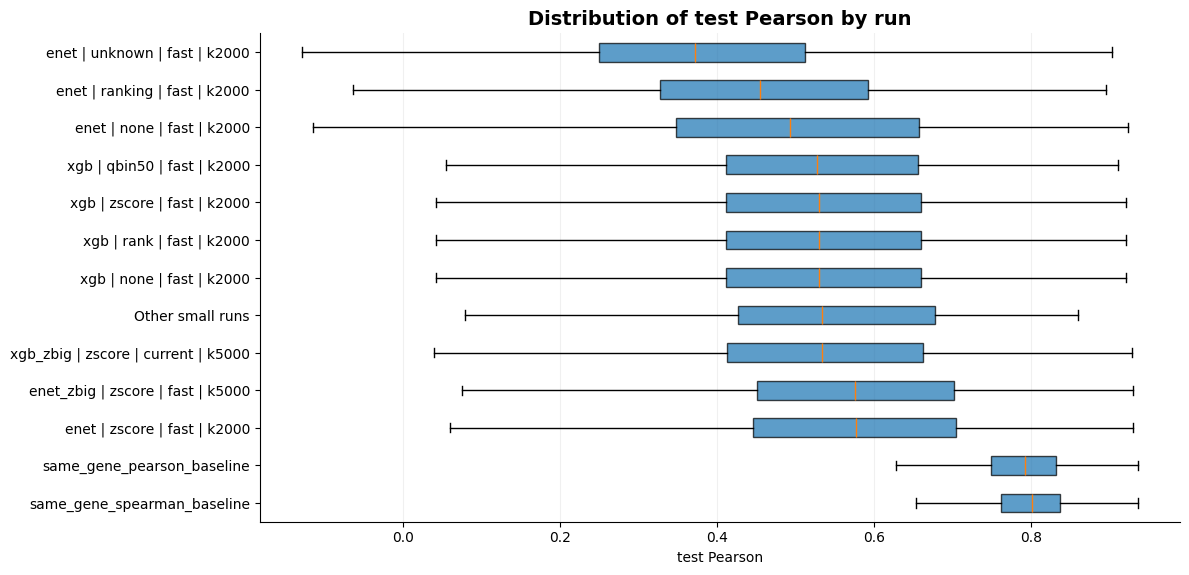

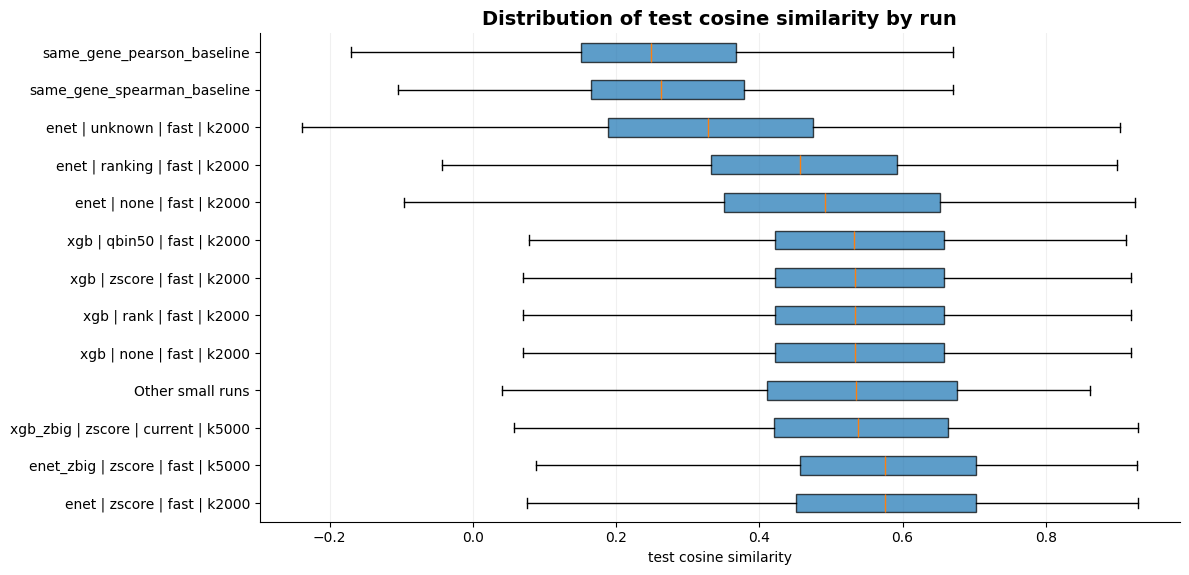

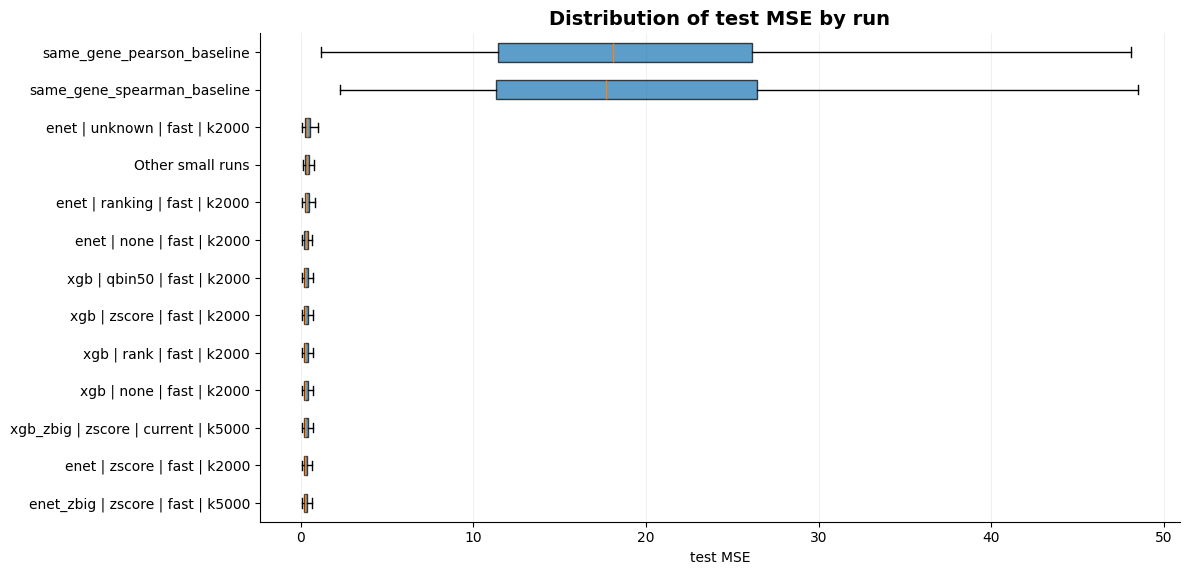

In [8]:
plot_metric_distributions(all_results)

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

## 8. Protein partition bars: which model/run predicts proteins well?

For each metric, the bar represents all proteins with a valid metric. Good proteins are assigned to the model/run that is best for that protein. Bad proteins are grouped in red.


test_pearson_corr family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 5113
Good proteins: 1427 (27.9%)
Bad proteins:  3686 (72.1%)
Good proteins best predicted by XGB:                244
Good proteins best predicted by ENet:               990
Good proteins best predicted by same-gene baseline: 193

Visible bar segments:


,partition_label,proteins,median_metric
0,enet_zbig | zscore | fast | k5000,436,0.765632
1,enet | zscore | fast | k2000,368,0.759896
2,Other good models (<200 proteins each),623,0.801761
3,Bad / test_pearson_corr < 0.7,3686,0.532886



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,median_metric
2,enet | none | fast | k2000,165,0.803244
3,xgb_zbig | zscore | current | k5000,124,0.777874
4,same_gene_pearson_baseline,102,0.820677
5,same_gene_spearman_baseline,91,0.820393
6,xgb | qbin50 | fast | k2000,50,0.796192
7,xgb | none | fast | k2000,27,0.765305
8,xgb | zscore | fast | k2000,25,0.781175
9,xgb | rank | fast | k2000,18,0.766166
10,enet | ranking | fast | k2000,11,0.788239
11,enet | unknown | fast | k2000,5,0.790157


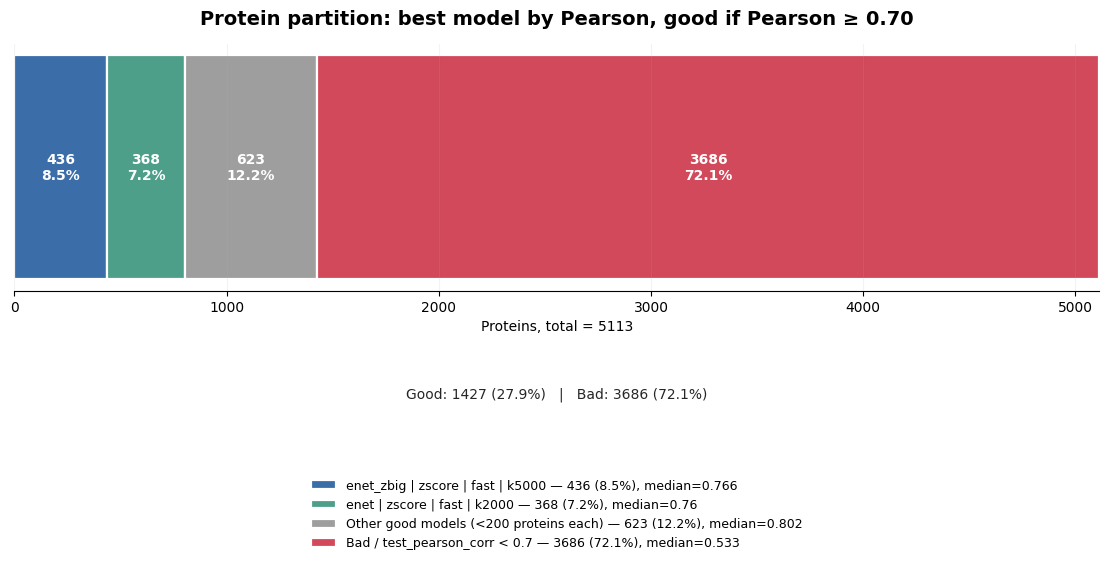


test_cosine_similarity family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 5113
Good proteins: 1427 (27.9%)
Bad proteins:  3686 (72.1%)
Good proteins best predicted by XGB:                264
Good proteins best predicted by ENet:               1163

Visible bar segments:


,partition_label,proteins,median_metric
0,enet_zbig | zscore | fast | k5000,495,0.772566
1,enet | zscore | fast | k2000,411,0.765593
2,enet | none | fast | k2000,218,0.802352
3,Other good models (<200 proteins each),303,0.786334
4,Bad / test_cosine_similarity < 0.7,3686,0.538288



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,median_metric
3,xgb_zbig | zscore | current | k5000,140,0.782970
4,xgb | qbin50 | fast | k2000,53,0.803460
5,xgb | none | fast | k2000,31,0.789985
6,xgb | zscore | fast | k2000,25,0.751445
7,enet | ranking | fast | k2000,21,0.808982
8,xgb | rank | fast | k2000,15,0.752550
9,enet | unknown | fast | k2000,12,0.789729
10,enet | zscore | fast | k500,5,0.752397
11,enet | none | fast | k500,1,0.804383


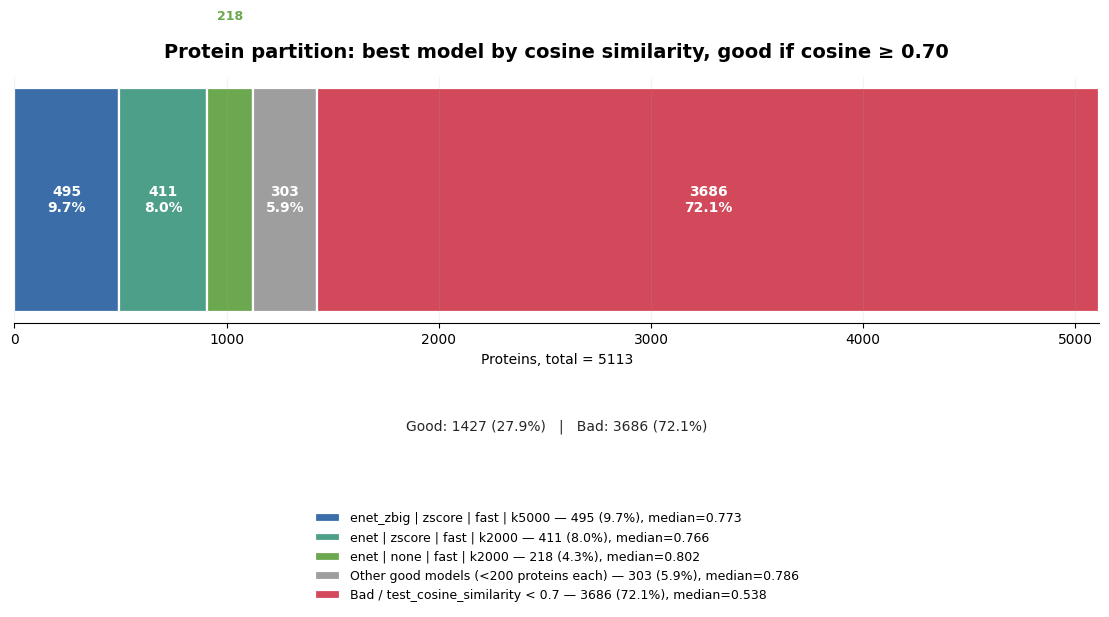


test_mse family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 5113
Good proteins: 1279 (25.0%)
Bad proteins:  3834 (75.0%)
Good proteins best predicted by XGB:                523
Good proteins best predicted by ENet:               756

Visible bar segments:


,partition_label,proteins,median_metric
0,enet_zbig | zscore | fast | k5000,429,0.150702
1,xgb_zbig | zscore | current | k5000,206,0.143190
2,Other good models (<200 proteins each),644,0.149085
3,Bad / test_mse > 0.182932,3834,0.293775



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,median_metric
2,enet | zscore | fast | k2000,194,0.151693
3,xgb | qbin50 | fast | k2000,154,0.145917
4,enet | none | fast | k2000,67,0.155073
5,xgb | none | fast | k2000,64,0.147023
6,xgb | zscore | fast | k2000,58,0.151057
7,enet | ranking | fast | k2000,50,0.139284
8,xgb | rank | fast | k2000,41,0.153398
9,enet | unknown | fast | k2000,16,0.131929


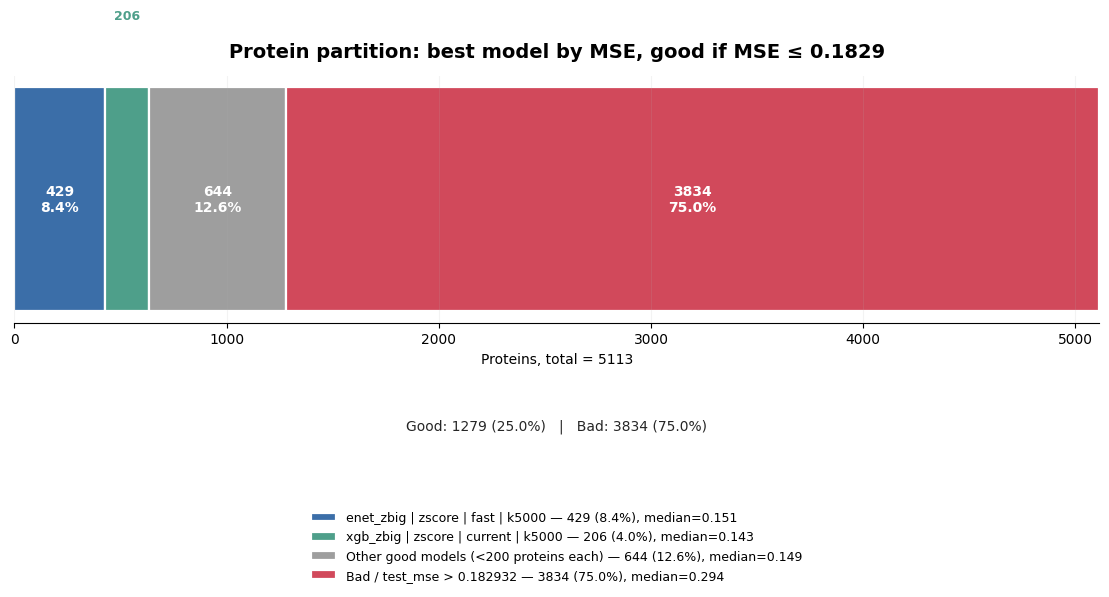

In [9]:
partition_pearson = plot_partition_bar(
    best_pearson,
    metric="test_pearson_corr",
    threshold=PEARSON_GOOD_THRESHOLD,
    higher=True,
    title=f"Protein partition: best model by Pearson, good if Pearson ≥ {PEARSON_GOOD_THRESHOLD:.2f}",
    min_proteins_to_show=MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT,
)

partition_cosine = plot_partition_bar(
    best_cosine,
    metric="test_cosine_similarity",
    threshold=COSINE_GOOD_THRESHOLD,
    higher=True,
    title=f"Protein partition: best model by cosine similarity, good if cosine ≥ {COSINE_GOOD_THRESHOLD:.2f}",
    min_proteins_to_show=MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT,
)

partition_mse = plot_partition_bar(
    best_mse,
    metric="test_mse",
    threshold=mse_threshold,
    higher=False,
    title=f"Protein partition: best model by MSE, good if MSE ≤ {mse_threshold:.4g}",
    min_proteins_to_show=MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT,
)

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

## 9. Inspect one winning result

This cell loads only metadata from the selected row. It does not retrain models.

In [10]:
if len(best_pearson) == 0:
    print("No best Pearson row available.")
else:
    row = best_pearson.iloc[0]
    print("Best Pearson example")
    print("- Protein:", row["protein"])
    print("- Run label:", row["run_label"])
    print("- Pearson:", row["test_pearson_corr"])
    print("- Cosine:", row["test_cosine_similarity"])
    print("- MSE:", row["test_mse"])
    print("- Path:", row.get("h5_path", ""))
    print("- Params:", row.get("best_params", {}))

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Best Pearson example
- Protein: ALDH1A1
- Run label: same_gene_spearman_baseline
- Pearson: 0.9369622027647851
- Cosine: 0.6373849830256054
- MSE: 16.484643967961293
- Path: 
- Params: {'baseline': 'same_name_gene_value', 'full_corr_threshold': 0.7, 'scaled': False, 'test_split_source': 'read_from_xgb_enet_h5'}


## 10. Optional saving/export cell

The following cell is intentionally commented out, as requested. Uncomment when exports are needed.

In [11]:
# OUT_DIR = ROOT / "comparison_with_gene_baselines_outputs"
# OUT_DIR.mkdir(parents=True, exist_ok=True)
#
# all_results.to_csv(OUT_DIR / "all_model_and_baseline_metrics.csv", index=False)
# same_gene_baselines.to_csv(OUT_DIR / "same_gene_baseline_metrics.csv", index=False)
# best_pearson.to_csv(OUT_DIR / "best_by_pearson.csv", index=False)
# best_cosine.to_csv(OUT_DIR / "best_by_cosine.csv", index=False)
# best_mse.to_csv(OUT_DIR / "best_by_mse.csv", index=False)
# partition_pearson.to_csv(OUT_DIR / "partition_by_pearson.csv", index=False)
# partition_cosine.to_csv(OUT_DIR / "partition_by_cosine.csv", index=False)
# partition_mse.to_csv(OUT_DIR / "partition_by_mse.csv", index=False)
#
# print("Saved outputs to:", OUT_DIR)

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

## Plots

In [12]:
# ============================================================
# Detailed per-model/per-run metric plots from all_results
# Paste this at the end of the notebook, after all_results exists.
# ============================================================

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import h5py
except Exception:
    h5py = None

# -----------------------------
# Plot output/settings
# -----------------------------
DETAILED_PLOT_DIR = Path("detailed_metric_plots")
DETAILED_PLOT_DIR.mkdir(parents=True, exist_ok=True)

DETAILED_SAVE_FIGURES = True
DETAILED_SHOW_FIGURES = True
DETAILED_DPI = 160

# If True, tries to estimate R2 from test_mse and Y/test samples.
# This can be slower because it may open many .h5 files.
# Keep False unless we specifically need R2.
DETAILED_ESTIMATE_R2 = False

# If True, includes the same-gene baselines in the automatic plotting loop.
DETAILED_INCLUDE_BASELINES = True

# Set to 1 for literally every run label.
# Set to 200 if we want to skip tiny 5/50-protein test runs.
DETAILED_MIN_PROTEINS_PER_RUN = 1


_TEST_SAMPLE_CACHE = {}


print("Detailed plotting functions loaded.")
print("Output folder:", DETAILED_PLOT_DIR.resolve())

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Detailed plotting functions loaded.
Output folder: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\detailed_metric_plots


Plotting 12 run labels
--------------------------------------------------------------------------------
enet | none | fast | k2000  |  proteins=5113
enet_zbig | zscore | fast | k5000  |  proteins=5113
xgb | zscore | fast | k2000  |  proteins=5113
xgb | rank | fast | k2000  |  proteins=5113
xgb | qbin50 | fast | k2000  |  proteins=5113
xgb | none | fast | k2000  |  proteins=5113
xgb_zbig | zscore | current | k5000  |  proteins=5113
enet | zscore | fast | k2000  |  proteins=5113
enet | unknown | fast | k2000  |  proteins=5113
enet | ranking | fast | k2000  |  proteins=5113
same_gene_pearson_baseline  |  proteins=786
same_gene_spearman_baseline  |  proteins=615

Plotting: enet | none | fast | k2000
Saved: detailed_metric_plots\detailed_enet_none_fast_k2000.png


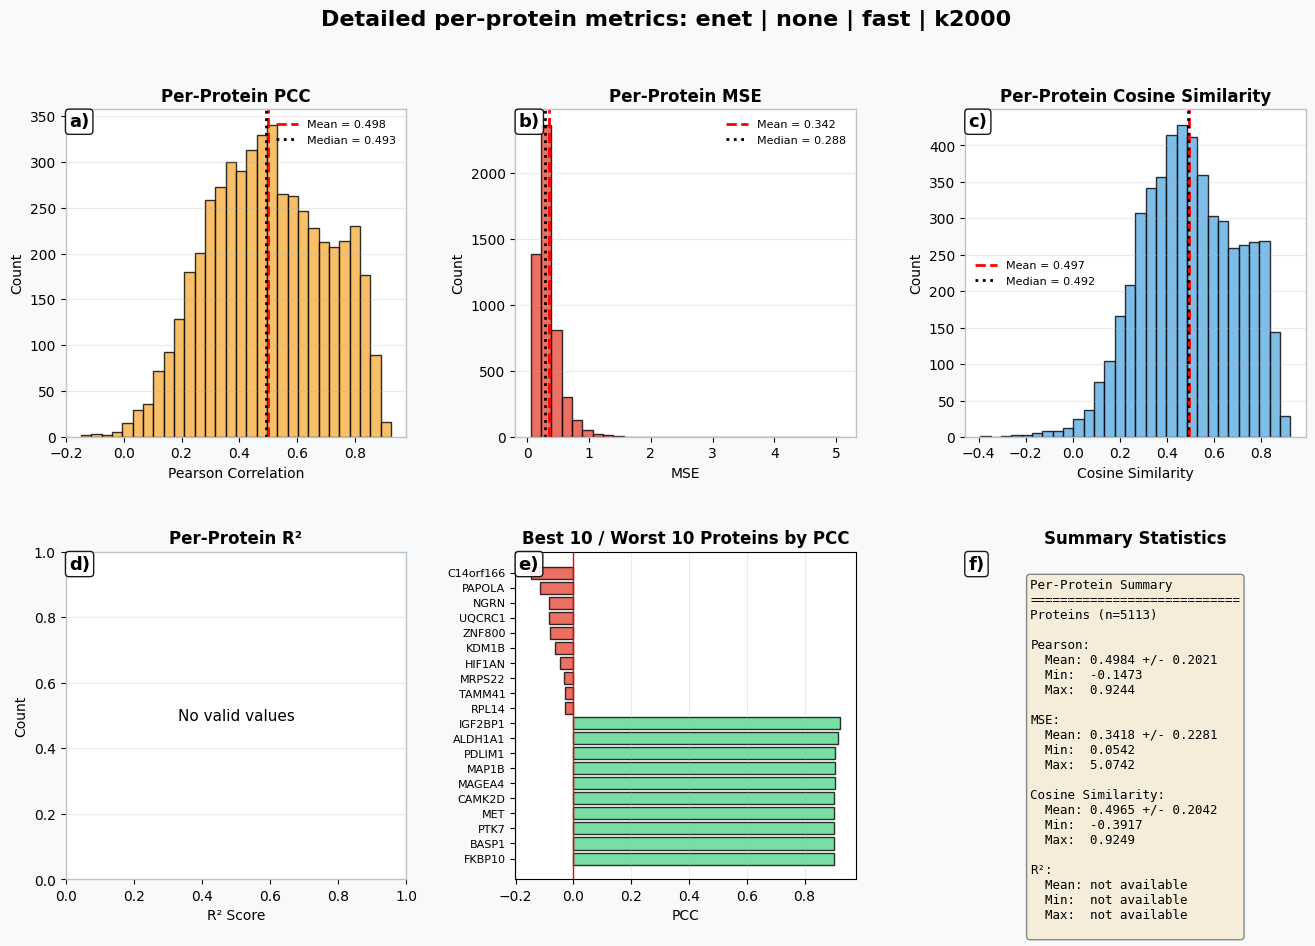


Plotting: enet_zbig | zscore | fast | k5000
Saved: detailed_metric_plots\detailed_enet_zbig_zscore_fast_k5000.png


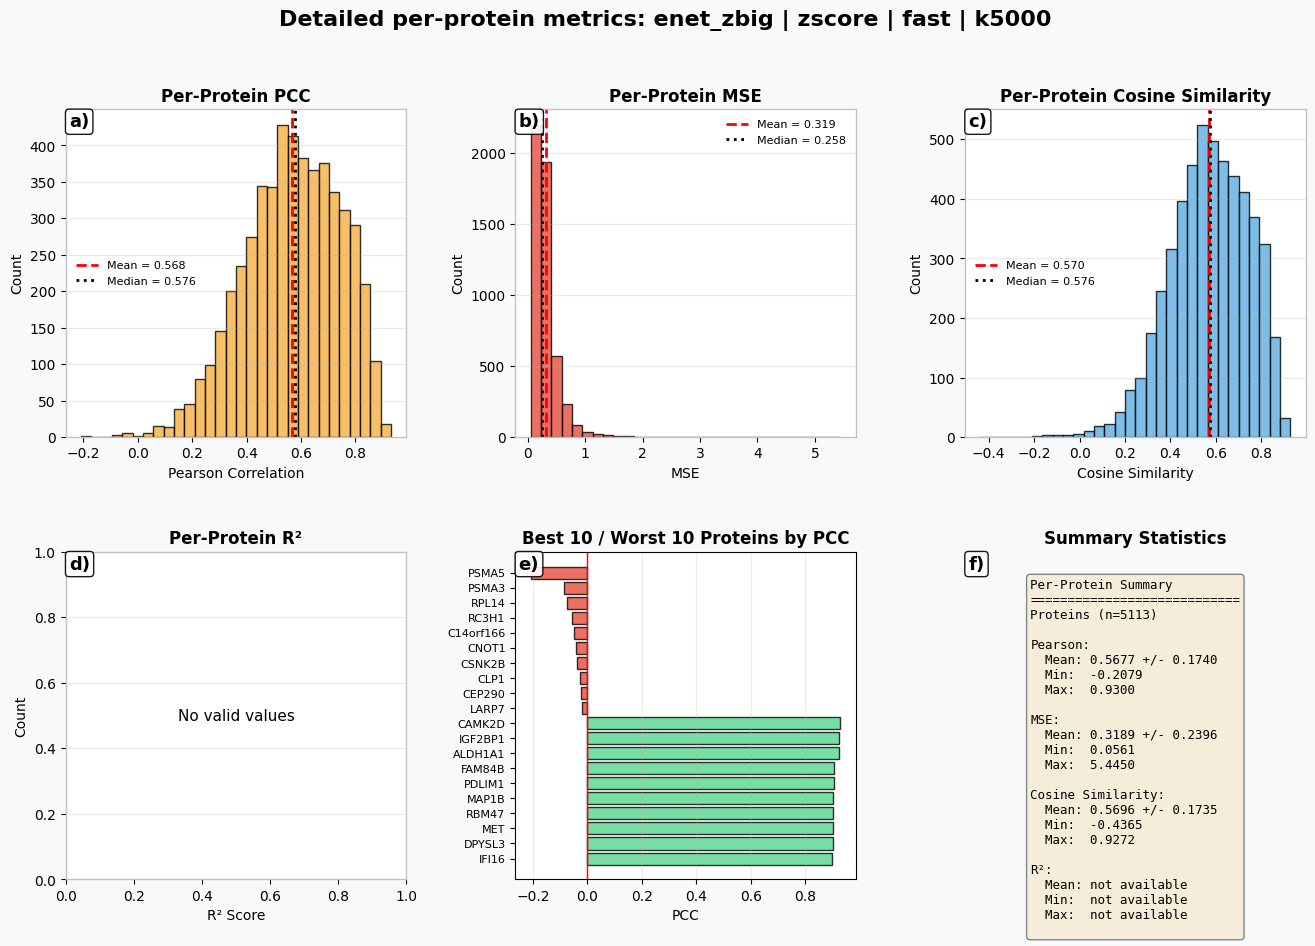


Plotting: xgb | zscore | fast | k2000
Saved: detailed_metric_plots\detailed_xgb_zscore_fast_k2000.png


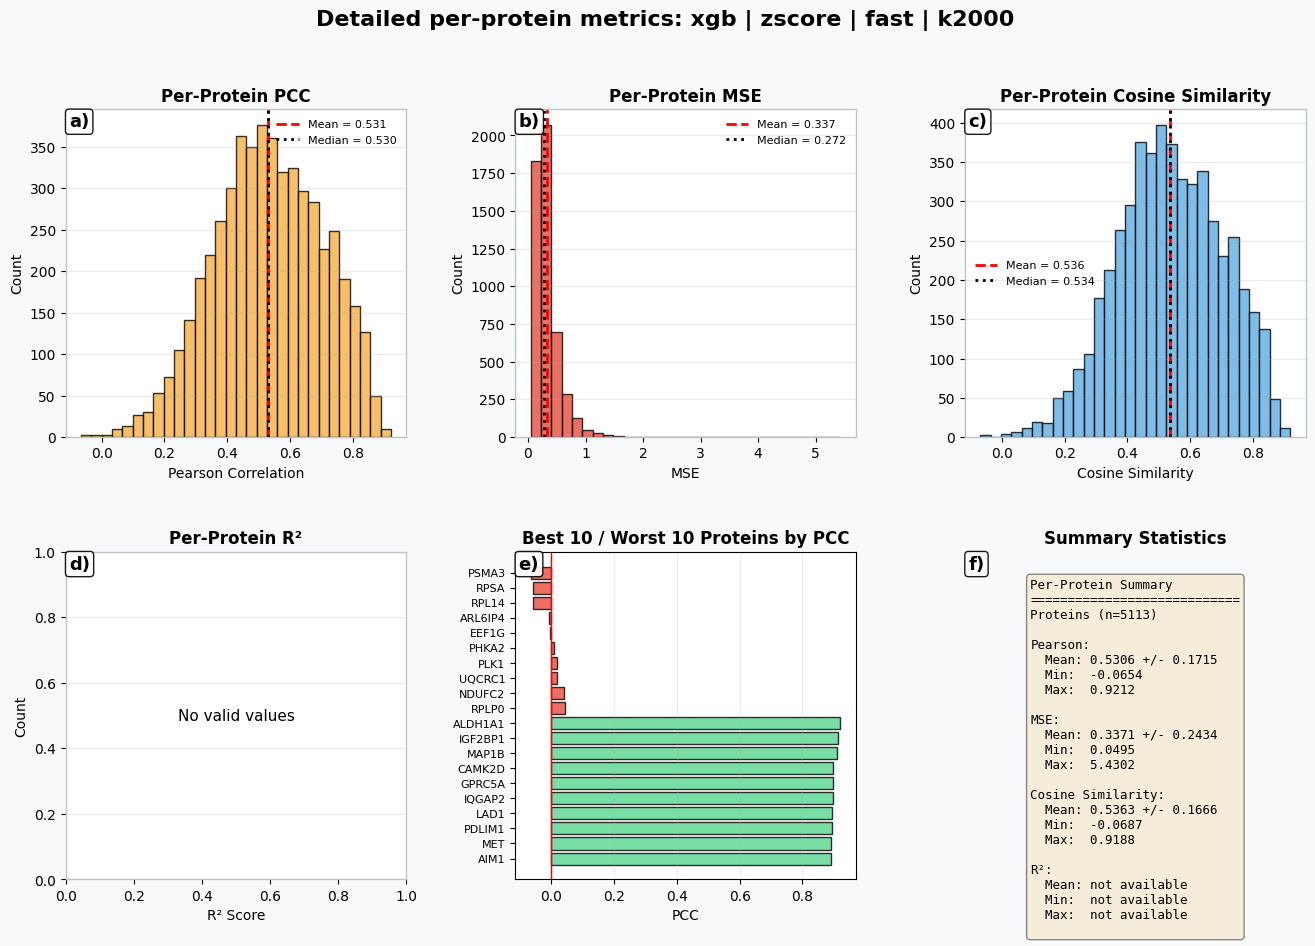


Plotting: xgb | rank | fast | k2000
Saved: detailed_metric_plots\detailed_xgb_rank_fast_k2000.png


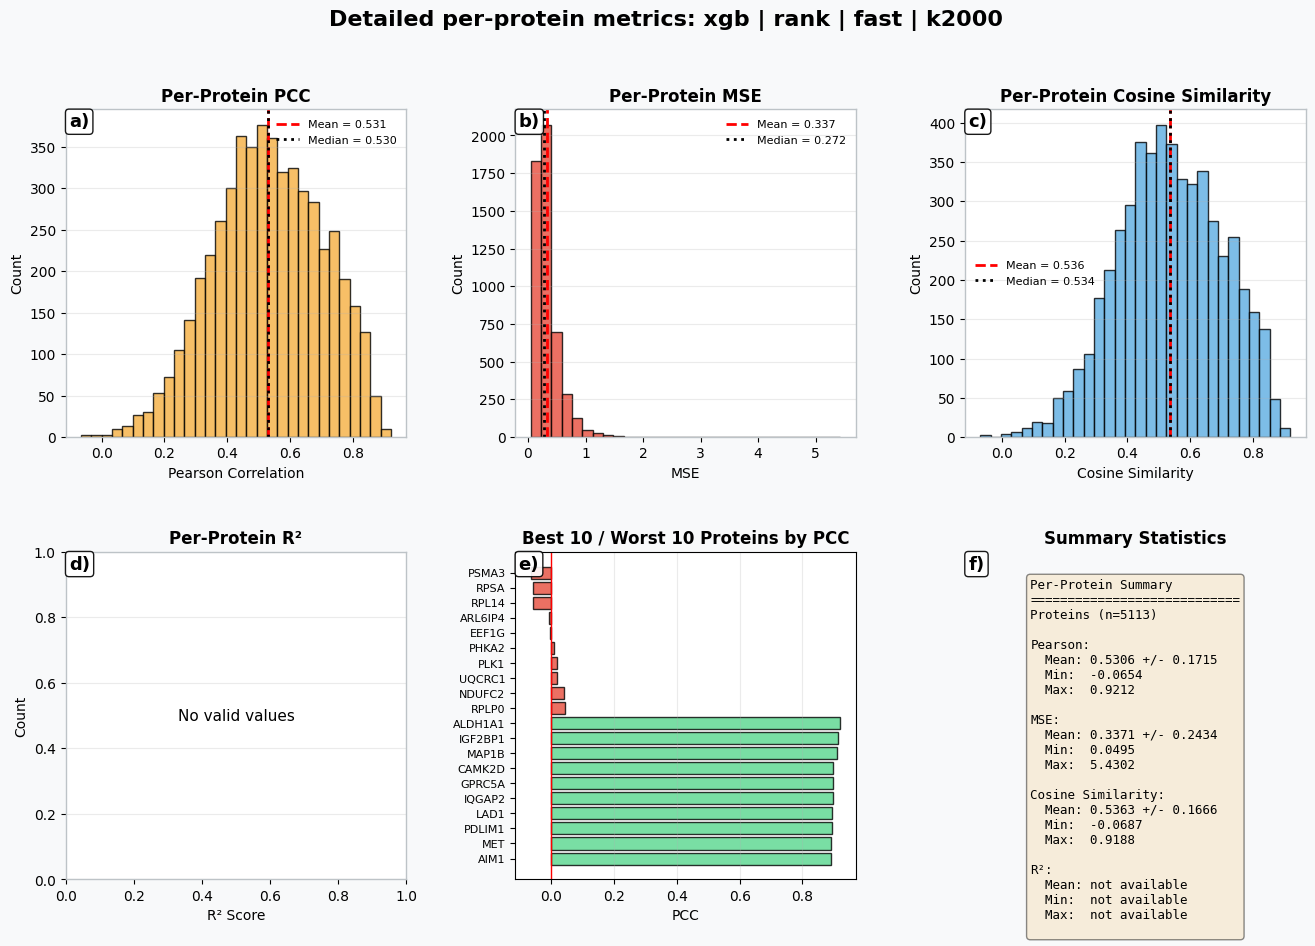


Plotting: xgb | qbin50 | fast | k2000
Saved: detailed_metric_plots\detailed_xgb_qbin50_fast_k2000.png


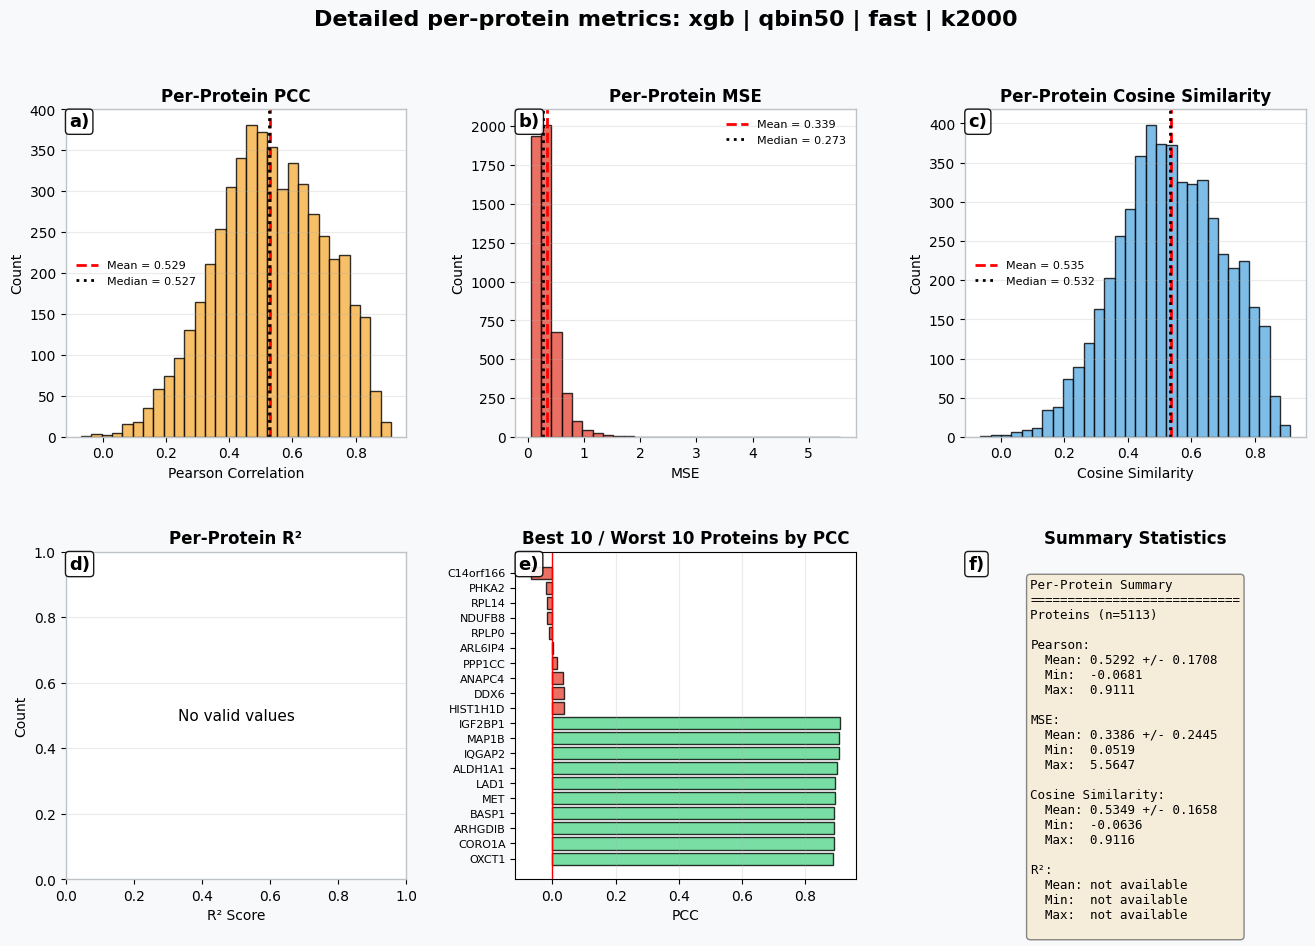


Plotting: xgb | none | fast | k2000
Saved: detailed_metric_plots\detailed_xgb_none_fast_k2000.png


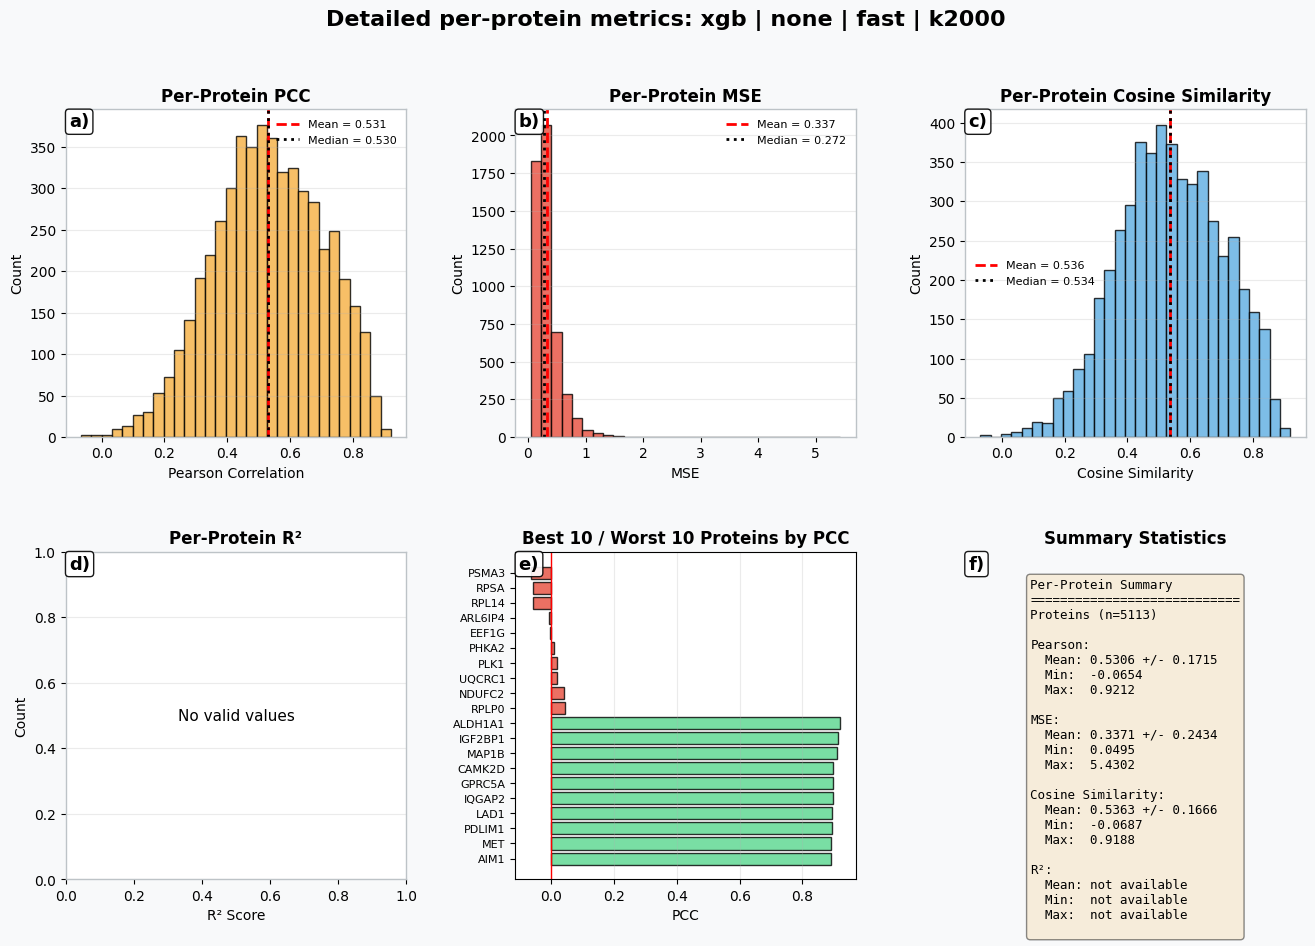


Plotting: xgb_zbig | zscore | current | k5000
Saved: detailed_metric_plots\detailed_xgb_zbig_zscore_current_k5000.png


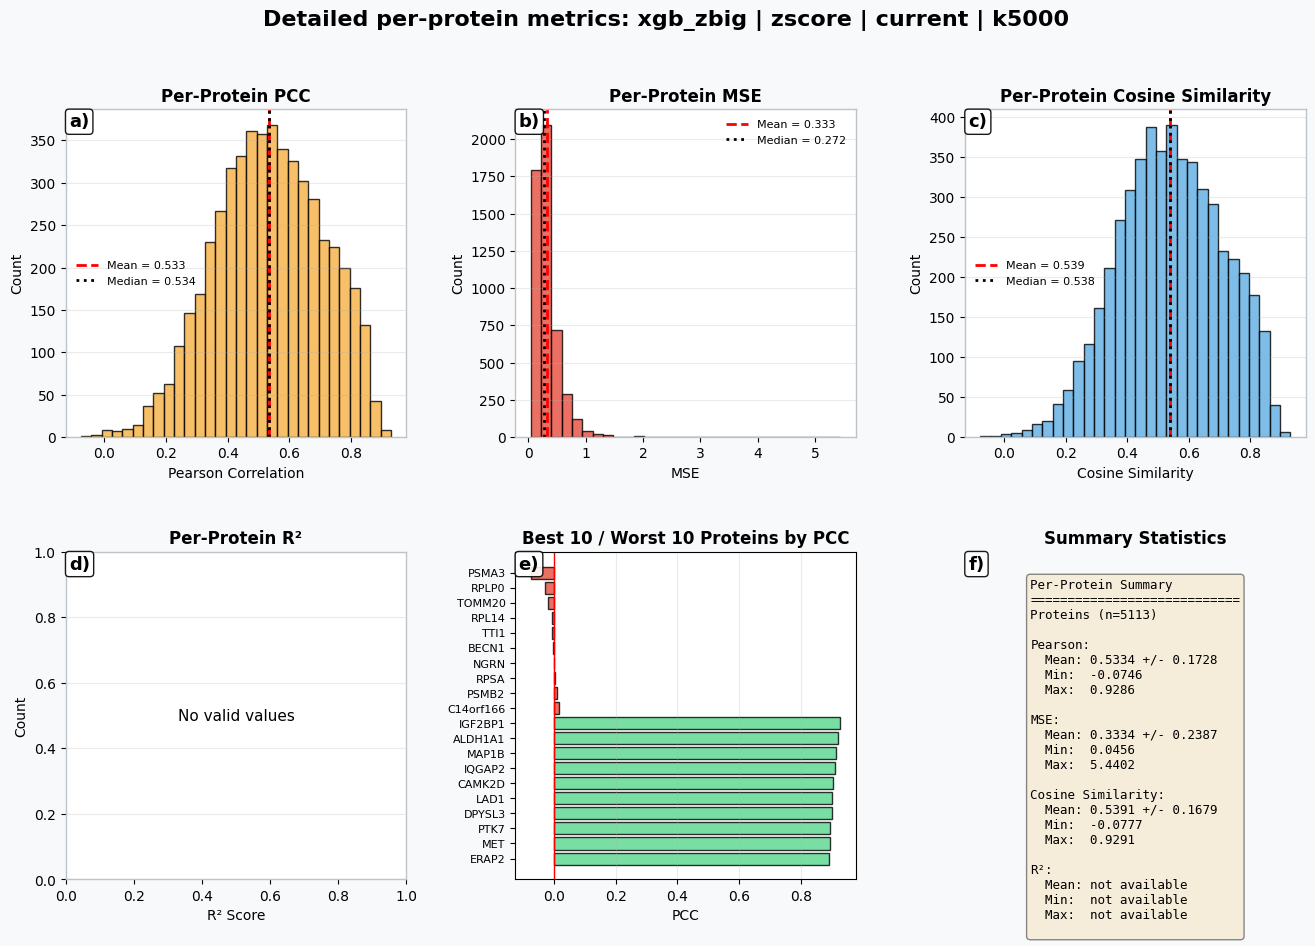


Plotting: enet | zscore | fast | k2000
Saved: detailed_metric_plots\detailed_enet_zscore_fast_k2000.png


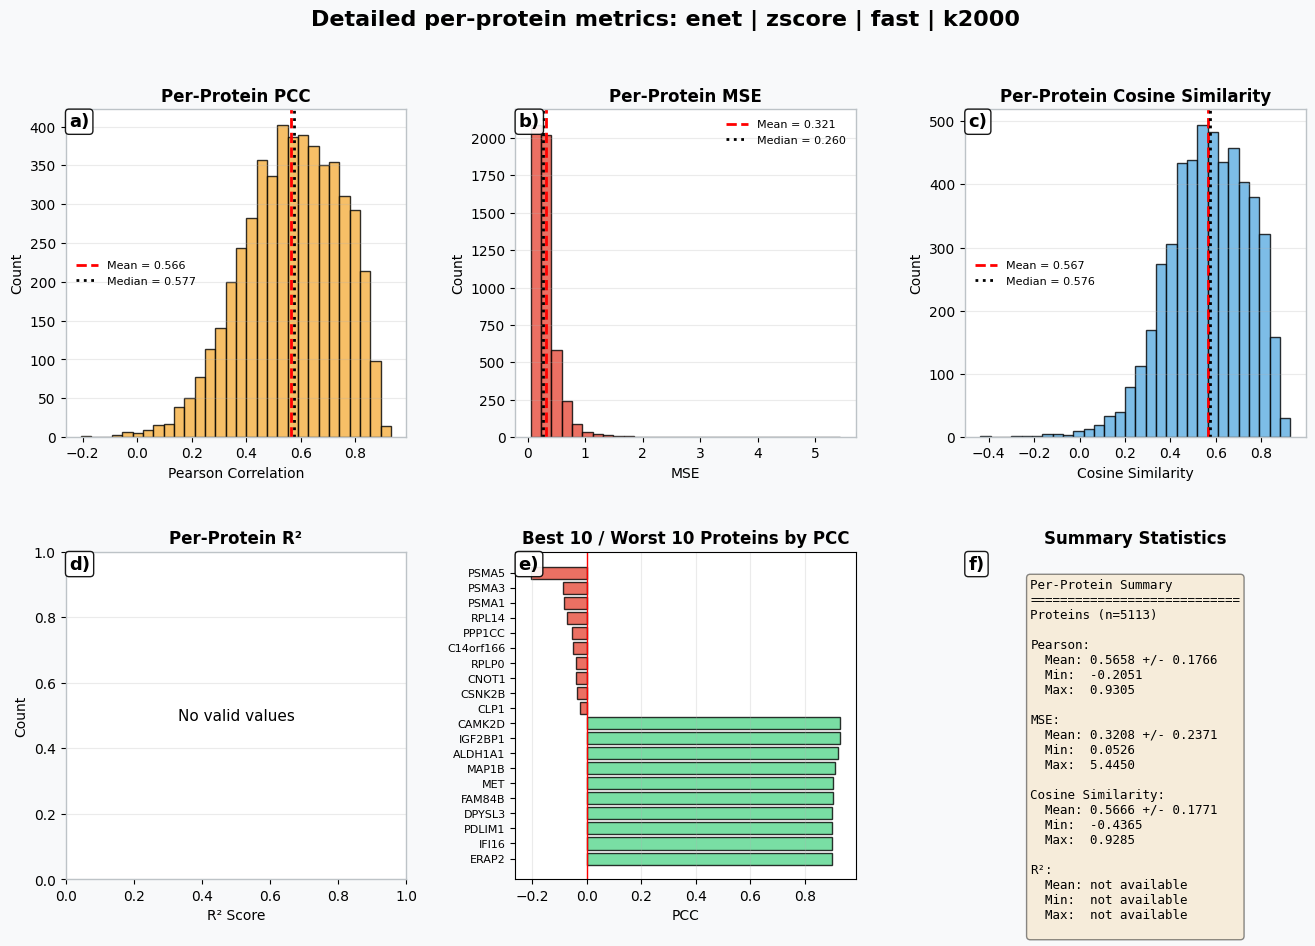


Plotting: enet | unknown | fast | k2000
Saved: detailed_metric_plots\detailed_enet_unknown_fast_k2000.png


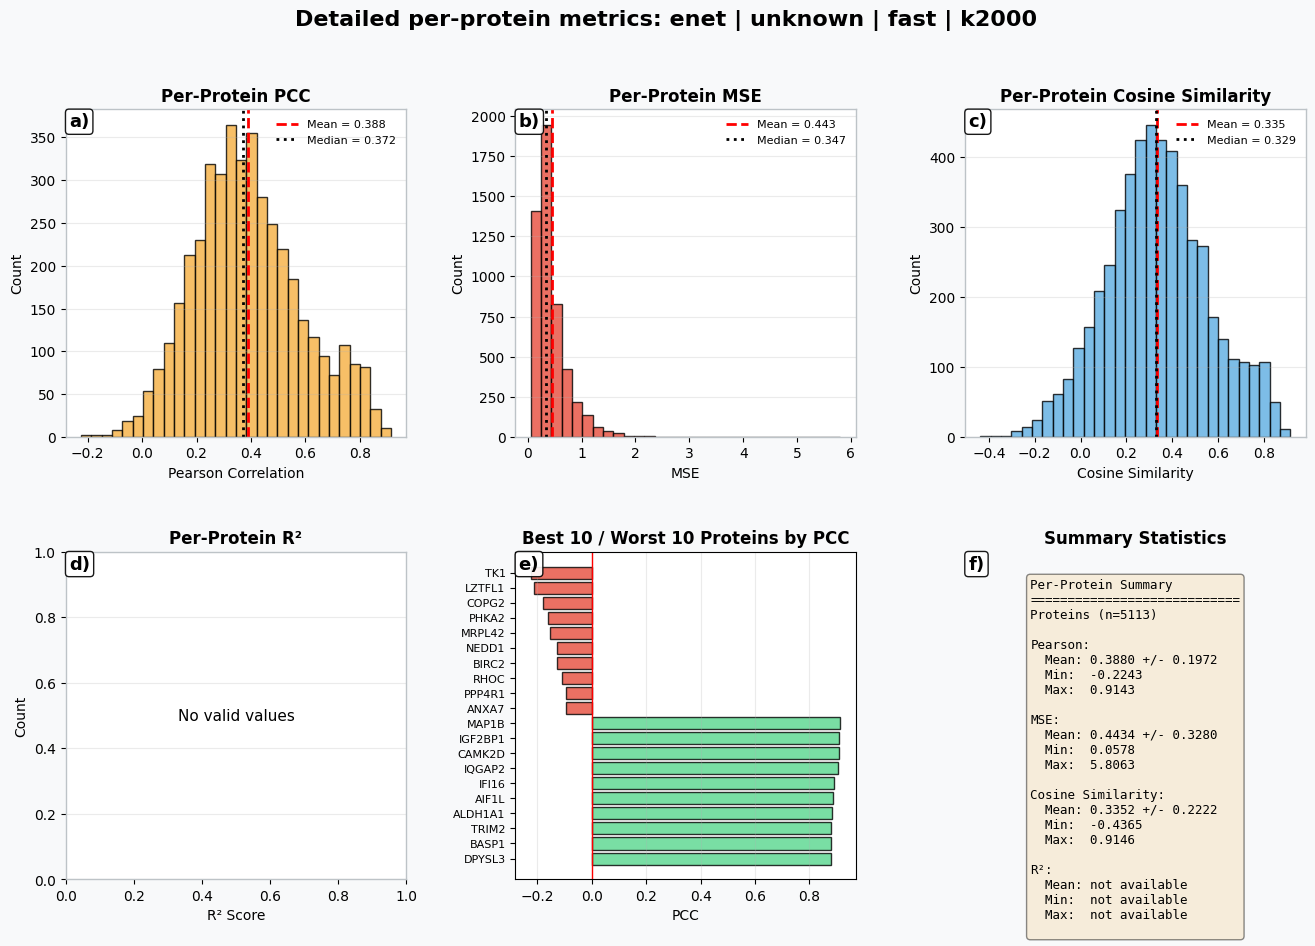


Plotting: enet | ranking | fast | k2000
Saved: detailed_metric_plots\detailed_enet_ranking_fast_k2000.png


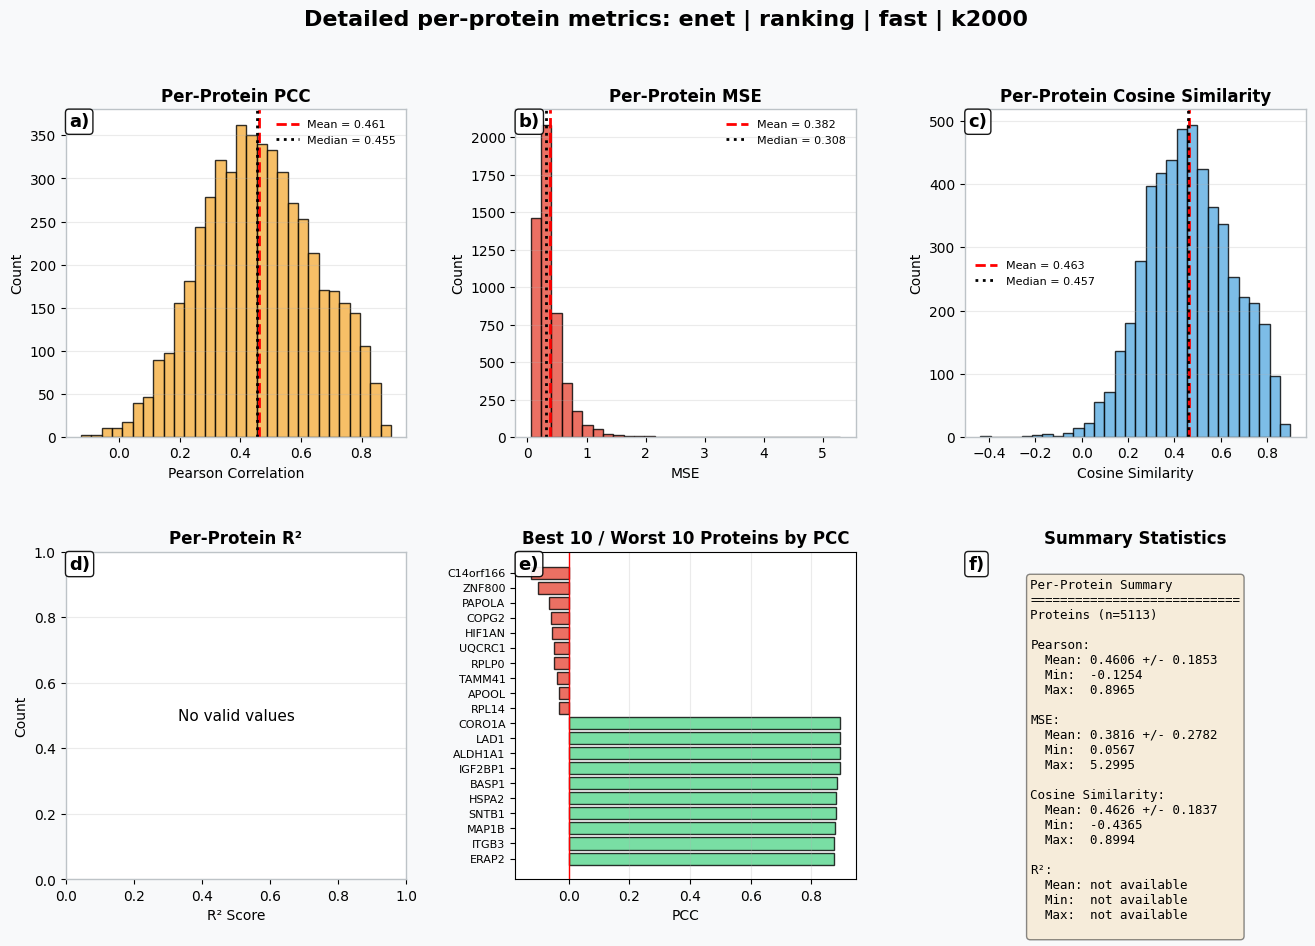


Plotting: same_gene_pearson_baseline
Saved: detailed_metric_plots\detailed_same_gene_pearson_baseline.png


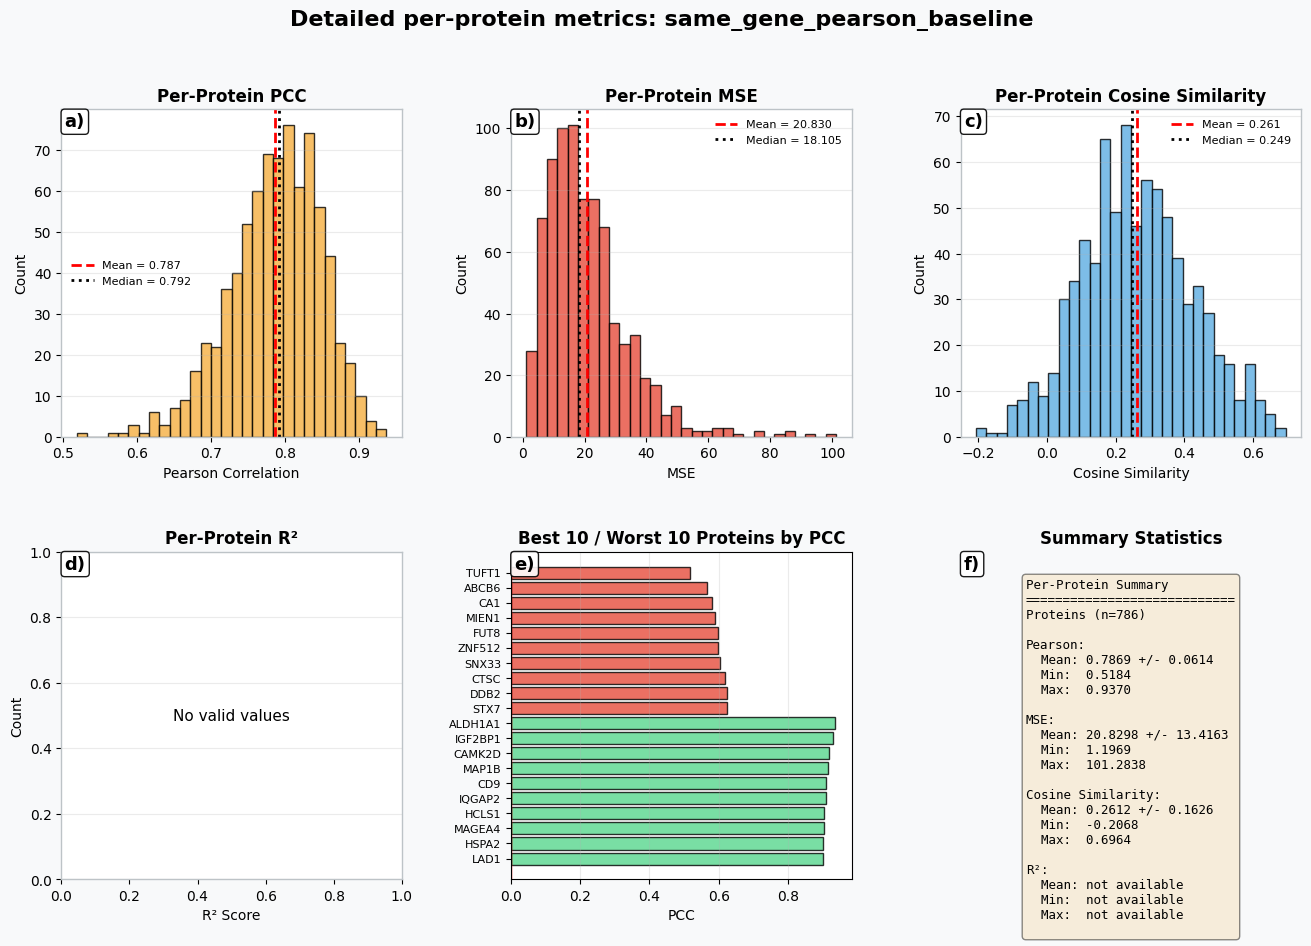


Plotting: same_gene_spearman_baseline
Saved: detailed_metric_plots\detailed_same_gene_spearman_baseline.png


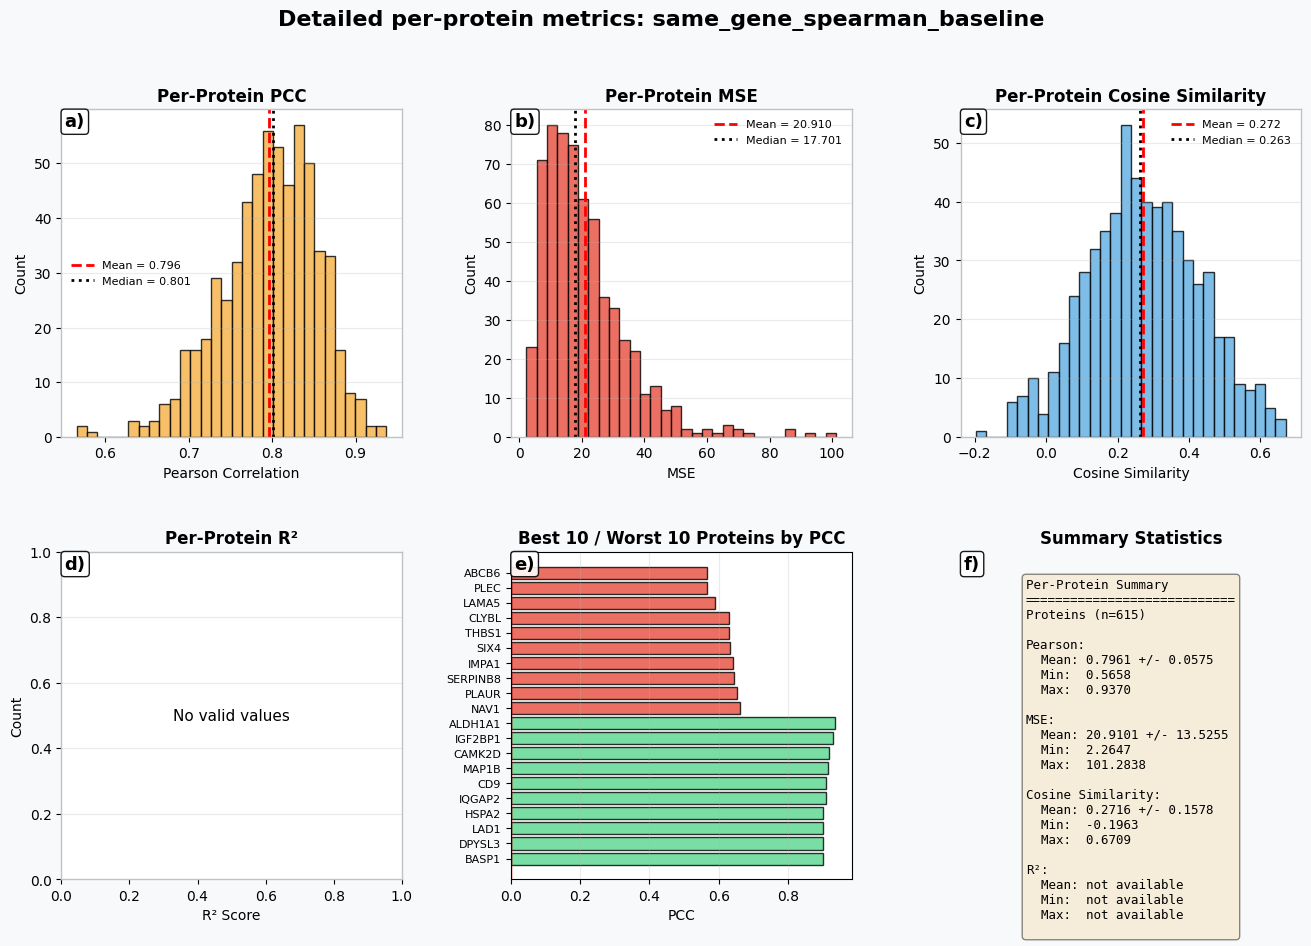

In [13]:
detailed_outputs_full_runs = plot_detailed_for_all_run_labels(
    all_results,
    min_proteins=200,
    include_baselines=True,
    estimate_r2=False,
    save=True,
    show=True,
    out_dir=DETAILED_PLOT_DIR,
)

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass